In [9]:
from matplotlib.colors import LogNorm
import seaborn as sns
import numpy as np
import pandas as pd
from utils import repeat, df_vals, melt_and_keep
import matplotlib.pyplot as plt
from ydata_profiling import ProfileReport


In [10]:
# df= pd.read_pickle("../data/jan_2025_10.pickle")
df= pd.read_pickle("../data/mylastdf.pickle")
profile = ProfileReport(df, title="Profiling Report")
profile.to_notebook_iframe()

ModuleNotFoundError: No module named 'numpy._core.numeric'

In [ ]:
thetime = df['runtime_seconds'].describe()
maxtime = thetime.mean() + thetime.std()
(15*60)/maxtime

10.345778566277856

In [ ]:
df_vals(df)

'm':
[   100    483   2330  11249  54304 262144]
----------------------------------------
'k':
[100]
----------------------------------------
'sigma':
[0.e+00 1.e-02 1.e+00 1.e+02]
----------------------------------------
'lambda_':
[1.e-04 1.e-06 1.e-08]
----------------------------------------
'max_iter':
[1000000.]
----------------------------------------
'img':
Categorical:  ['camera']
Categories (2, object): ['phantom', 'camera']
----------------------------------------
'sampling_type':
Categorical:  ['wr']
Categories (2, object): ['wr', 'Ber']
----------------------------------------
'adapted_sampling':
[ True]
----------------------------------------
'seed':
min: 55437432.00, max: 4239731024.00, mean: 2187084484.46, std: 1195776098.20
----------------------------------------
're':
min: 0.00, max: 1.03, mean: 0.22, std: 0.40
----------------------------------------
'runtime_seconds':
min: 3.17, max: 131.79, mean: 36.67, std: 42.25
----------------------------------------
'indices

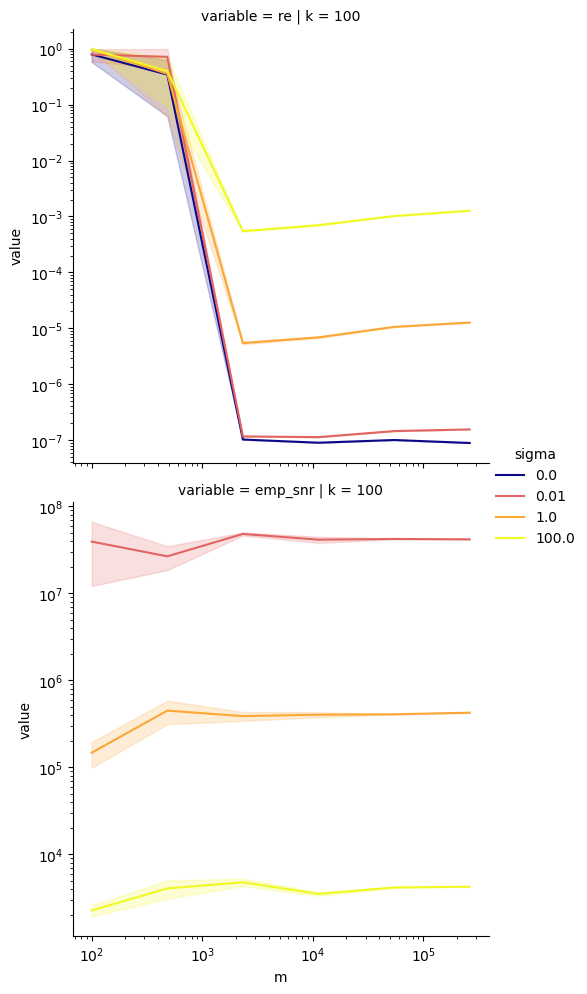

In [ ]:
# df_wr = df[df['sampling_type']=='wr']
# mydf = df_wr[df_wr['adapted_sampling']==True]
# mydf = df_wr[mydf['img']=="phantom"]
doubledf = melt_and_keep(mydf, ["re","emp_snr"])
g = sns.relplot(doubledf, kind = "line", x = "m", y="value", row ="variable", col="k", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se", facet_kws={'sharey':False})
for ax in g.axes.flat:
    ax.set_yscale('log')  # Set y-axis to log scale
plt.xscale("log")
# g=sns.relplot(mydf, kind = "line", x = "m", y="re", col="k", row="lambda_"  , hue="sigma", hue_norm=LogNorm(vmin=1e-4, clip=True), palette="plasma", errorbar="se", facet_kws={'sharey':False})
#doubledf=melt_and_keep(mydf, ["re","unique_meas"])

In [ ]:
melt_and_keep(mydf, ["re","emp_snr"]).columns

Index(['m', 'k', 'sigma', 'lambda_', 'max_iter', 'img', 'sampling_type',
       'adapted_sampling', 'seed', 'runtime_seconds', 'indices',
       'experiment_fn_label', 'm_tld', 'optim_info', 'variable', 'value'],
      dtype='object')

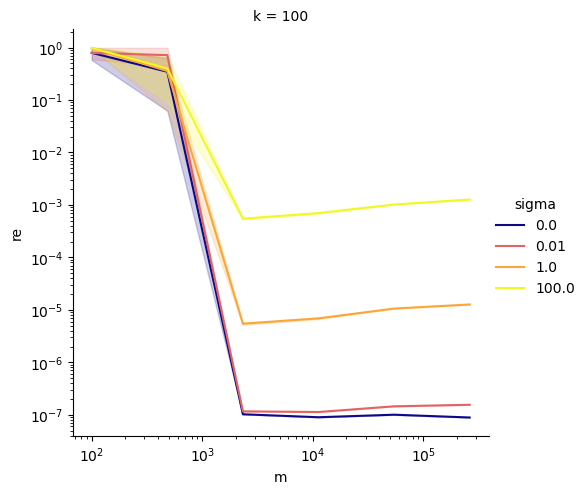

In [ ]:
%matplotlib inline
mydf['fixed_y'] = mydf.apply(lambda row:row['y']/np.sqrt(row['m']))
g = sns.relplot(mydf, kind = "line", x = "m", y="re", col="k", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se", facet_kws={'sharey':False})
for ax in g.axes.flat:
    ax.set_yscale('log')  # Set y-axis to log scale
plt.xscale("log")

In [ ]:
kkjdf_wr

NameError: name 'kkjdf_wr' is not defined